# Topic 1 Practice — A Neural Network Forward Pass, Under the Hood

**Companion notebook for:** *From AI to Deep Learning: a practical map before learning architectures*

This notebook focuses on one question:

> **What actually happens to a few input numbers when they pass through a neural network and become one output number?**

There is **no training** in this notebook. The weights are fixed by hand so that every calculation is deterministic and easy to inspect.

### Learning goals

By the end, you should be able to:

- distinguish **input values**, **parameters**, **intermediate activations**, and **output**;
- explain a forward pass as repeated numerical transformations;
- read the shapes of weight matrices and activation vectors;
- see exactly how a `Linear` layer and `ReLU` change numbers;
- trace and visualize values as they move through a small deep network;
- understand why a network with untrained/arbitrary weights can produce a number but not a useful prediction.

**Estimated time:** 30–45 minutes.  
**Requirements:** Python only; no dataset, GPU, Google Drive, or training loop is needed.

## 1. Setup

The notebook uses NumPy, pandas, and Matplotlib for the main walkthrough. They are checked automatically so the notebook can be uploaded to Google Colab and run from top to bottom.

PyTorch is used only in an optional comparison section near the end. Colab commonly provides PyTorch in its runtime; if it is unavailable, that section will skip cleanly instead of breaking the notebook.

In [1]:
import importlib.util
import subprocess
import sys

required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
}

missing = [pip_name for module_name, pip_name in required_packages.items()
           if importlib.util.find_spec(module_name) is None]

if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
print("Setup complete.")
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

Setup complete.
NumPy: 2.5.0
pandas: 3.0.6


## 2. The model we will open up

We will use a tiny feedforward neural network:

$$
3\text{ inputs} \rightarrow 3\text{ hidden neurons} \rightarrow 2\text{ hidden neurons} \rightarrow 1\text{ output}
$$

The forward path is:

$$
\mathbf{x}
\rightarrow
\text{Linear}_1
\rightarrow
\text{ReLU}
\rightarrow
\text{Linear}_2
\rightarrow
\text{ReLU}
\rightarrow
\text{Linear}_3
\rightarrow
\text{Sigmoid}
\rightarrow
\text{score}
$$

This is already a **deep** network in the basic sense that the input is transformed through multiple layers.

For each linear layer:

$$
\mathbf{z} = W\mathbf{x} + \mathbf{b}
$$

Then ReLU is applied element by element:

$$
\operatorname{ReLU}(z)=\max(0,z)
$$

The final sigmoid maps one real number into the interval $(0,1)$:

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

Do not worry about memorizing these formulas yet. The goal is to watch the numbers move.

## 3. One input sample

We reuse the student-risk example from the reading. The three input features are normalized to roughly the same range:

- attendance rate = `0.75`;
- assignment submission rate = `0.60`;
- normalized midterm score = `0.55` (for example, 5.5/10).

These values are only an easy-to-read example. The network below is **not a real student-risk model**.

In [2]:
feature_names = ["attendance_rate", "submission_rate", "midterm_normalized"]
x = np.array([0.75, 0.60, 0.55], dtype=float)

input_table = pd.DataFrame({
    "feature": feature_names,
    "value": x,
})
input_table

,feature,value
0,attendance_rate,0.75
1,submission_rate,0.60
2,midterm_normalized,0.55


At this point, the model sees only the numerical vector

$$
\mathbf{x}=[0.75,\;0.60,\;0.55].
$$

The feature names are meaningful to us; the computation itself operates on numbers.

## 4. Fixed parameters: the numbers inside the model

A model architecture tells us **how layers are connected**. Parameters are the concrete numbers used by those layers.

For this demonstration, we choose all weights and biases manually. They will **not change** anywhere in the notebook.

In [3]:
# Layer 1: 3 inputs -> 3 hidden neurons
W1 = np.array([
    [ 0.8, -0.4,  0.5],
    [-0.3,  0.9,  0.2],
    [ 0.6,  0.1, -0.7],
], dtype=float)
b1 = np.array([0.10, -0.20, -0.15], dtype=float)

# Layer 2: 3 hidden values -> 2 hidden neurons
W2 = np.array([
    [ 0.7, -0.5,  0.4],
    [-0.2,  0.8,  0.6],
], dtype=float)
b2 = np.array([0.00, 0.10], dtype=float)

# Output layer: 2 hidden values -> 1 scalar
W3 = np.array([[1.2, -0.8]], dtype=float)
b3 = np.array([-0.10], dtype=float)

print("W1 shape:", W1.shape, "b1 shape:", b1.shape)
print("W2 shape:", W2.shape, "b2 shape:", b2.shape)
print("W3 shape:", W3.shape, "b3 shape:", b3.shape)

parameter_count = W1.size + b1.size + W2.size + b2.size + W3.size + b3.size
print("Total parameters:", parameter_count)

W1 shape: (3, 3) b1 shape: (3,)
W2 shape: (2, 3) b2 shape: (2,)
W3 shape: (1, 2) b3 shape: (1,)
Total parameters: 23


### Reading the shapes

`W1.shape == (3, 3)` means:

- 3 rows: three neurons in the next layer;
- 3 columns: each neuron receives three input values.

`W2.shape == (2, 3)` means two neurons, each receiving three values.

`W3.shape == (1, 2)` means one output neuron receiving two values.

The network has only **23 parameters**. Modern networks may have millions or billions, but the basic idea is still repeated numerical transformations using parameters.

## 5. Forward pass — Layer 1

A linear neuron computes a weighted sum plus a bias.

For neuron 1 of the first hidden layer:

$$
z^{(1)}_1
=0.8(0.75)-0.4(0.60)+0.5(0.55)+0.10.
$$

Let the computer show every contribution instead of hiding the calculation inside a library.

In [4]:
def explain_linear_layer(inputs, weights, biases, input_names, neuron_prefix):
    rows = []
    for neuron_idx in range(weights.shape[0]):
        contributions = weights[neuron_idx] * inputs
        row = {
            "neuron": f"{neuron_prefix}{neuron_idx + 1}",
            **{f"{name} contribution": value for name, value in zip(input_names, contributions)},
            "bias": biases[neuron_idx],
            "z (before activation)": contributions.sum() + biases[neuron_idx],
        }
        rows.append(row)
    return pd.DataFrame(rows)

layer1_breakdown = explain_linear_layer(
    x, W1, b1, feature_names, "h1_"
)
layer1_breakdown

,neuron,attendance_rate contribution,submission_rate contribution,midterm_normalized contribution,bias,z (before activation)
0,h1_1,0.600,-0.24,0.275,0.10,0.735
1,h1_2,-0.225,0.54,0.110,-0.20,0.225
2,h1_3,0.450,0.06,-0.385,-0.15,-0.025


In [5]:
z1 = W1 @ x + b1
z1

array([ 0.735,  0.225, -0.025])

The vector `z1` is the output of the first **linear transformation**, before the activation function.

Notice that the third value is negative. ReLU will make this visible.

In [6]:
def relu(values):
    return np.maximum(0, values)

a1 = relu(z1)

pd.DataFrame({
    "neuron": ["h1_1", "h1_2", "h1_3"],
    "before ReLU (z1)": z1,
    "after ReLU (a1)": a1,
})

,neuron,before ReLU (z1),after ReLU (a1)
0,h1_1,0.735,0.735
1,h1_2,0.225,0.225
2,h1_3,-0.025,0.000


ReLU keeps positive values and replaces negative values with zero.

So the first hidden representation is approximately:

$$
\mathbf{a}^{(1)}=[0.735,\;0.225,\;0].
$$

The network is no longer working directly with attendance, submissions, and midterm score. It is now working with a new internal representation produced by the first layer.

## 6. Forward pass — Layer 2

The second layer does exactly the same kind of operation, but its input is now the activation vector produced by Layer 1.

In [7]:
layer1_names = ["h1_1", "h1_2", "h1_3"]
layer2_breakdown = explain_linear_layer(
    a1, W2, b2, layer1_names, "h2_"
)
layer2_breakdown

,neuron,h1_1 contribution,h1_2 contribution,h1_3 contribution,bias,z (before activation)
0,h2_1,0.5145,-0.1125,0.0,0.0,0.402
1,h2_2,-0.1470,0.1800,0.0,0.1,0.133


In [8]:
z2 = W2 @ a1 + b2
a2 = relu(z2)

pd.DataFrame({
    "neuron": ["h2_1", "h2_2"],
    "before ReLU (z2)": z2,
    "after ReLU (a2)": a2,
})

,neuron,before ReLU (z2),after ReLU (a2)
0,h2_1,0.402,0.402
1,h2_2,0.133,0.133


The network has compressed three hidden values into two new hidden values:

$$
\mathbf{a}^{(2)}\approx[0.402,\;0.133].
$$

Again, there is nothing mysterious happening between layers: numbers go in, a mathematical transformation is applied, and new numbers come out.

## 7. Forward pass — From hidden values to one number

The output layer converts the two hidden values into one raw scalar, often called a **logit** in classification models.

In [9]:
output_breakdown = explain_linear_layer(
    a2, W3, b3, ["h2_1", "h2_2"], "output_"
)
output_breakdown

,neuron,h2_1 contribution,h2_2 contribution,bias,z (before activation)
0,output_1,0.4824,-0.1064,-0.1,0.276


In [10]:
def sigmoid(value):
    return 1.0 / (1.0 + np.exp(-value))

logit = (W3 @ a2 + b3)[0]
score = sigmoid(logit)

print(f"Raw output / logit: {logit:.6f}")
print(f"After sigmoid:       {score:.6f}")

Raw output / logit: 0.276000
After sigmoid:       0.568565


The final score is approximately **0.569**.

If this were a trained binary classifier, a value in $(0,1)$ could be interpreted according to the way the model was trained and calibrated. Here, however, the parameters were invented by us.

> **Important:** producing a plausible-looking number does not mean the model has learned anything.

This network currently demonstrates **inference / forward propagation only**. Training would be the process that adjusts the parameters using data and an objective. That comes later in the series.

## 8. Put the whole forward pass in one function

Real models do not usually expose every calculation line by line. We package the same operations into a `forward` function, while still returning a trace for inspection.

In [11]:
def forward_with_trace(inputs):
    trace = {}
    trace["input"] = inputs.copy()

    trace["layer1_pre_relu"] = W1 @ inputs + b1
    trace["layer1_post_relu"] = relu(trace["layer1_pre_relu"])

    trace["layer2_pre_relu"] = W2 @ trace["layer1_post_relu"] + b2
    trace["layer2_post_relu"] = relu(trace["layer2_pre_relu"])

    trace["logit"] = W3 @ trace["layer2_post_relu"] + b3
    trace["score"] = sigmoid(trace["logit"])
    return trace

trace = forward_with_trace(x)

for name, value in trace.items():
    print(f"{name:22s} -> {np.asarray(value)}")

input                  -> [0.75 0.6  0.55]
layer1_pre_relu        -> [ 0.735  0.225 -0.025]
layer1_post_relu       -> [0.735 0.225 0.   ]
layer2_pre_relu        -> [0.402 0.133]
layer2_post_relu       -> [0.402 0.133]
logit                  -> [0.276]
score                  -> [0.5686]


In [12]:
x_ex1 = np.array([0.95, 0.90, 0.80])
trace_ex1 = forward_with_trace(x_ex1)

for name, value in trace_ex1.items():
    print(f"{name:22s} -> {np.asarray(value)}")

input                  -> [0.95 0.9  0.8 ]
layer1_pre_relu        -> [ 0.9    0.485 -0.05 ]
layer1_post_relu       -> [0.9   0.485 0.   ]
layer2_pre_relu        -> [0.3875 0.308 ]
layer2_post_relu       -> [0.3875 0.308 ]
logit                  -> [0.1186]
score                  -> [0.5296]


In [13]:
# A small correctness check: the packaged forward pass must reproduce our manual result.
assert np.allclose(trace["layer1_pre_relu"], z1)
assert np.allclose(trace["layer1_post_relu"], a1)
assert np.allclose(trace["layer2_pre_relu"], z2)
assert np.allclose(trace["layer2_post_relu"], a2)
assert np.allclose(trace["logit"][0], logit)
assert np.allclose(trace["score"][0], score)

print("Check passed: the compact forward function matches the step-by-step calculation.")

Check passed: the compact forward function matches the step-by-step calculation.


## 9. Visualize the values moving through the network

The next figure is a map of one forward pass.

- Each circle is a value at one stage of the model.
- Solid connections represent positive weights.
- Dashed connections represent negative weights.
- Thicker connections have larger absolute weights.
- Node labels show the activation value for this particular input sample.

This is **not** a picture of neurons inside a brain. It is a visualization of a computation graph.

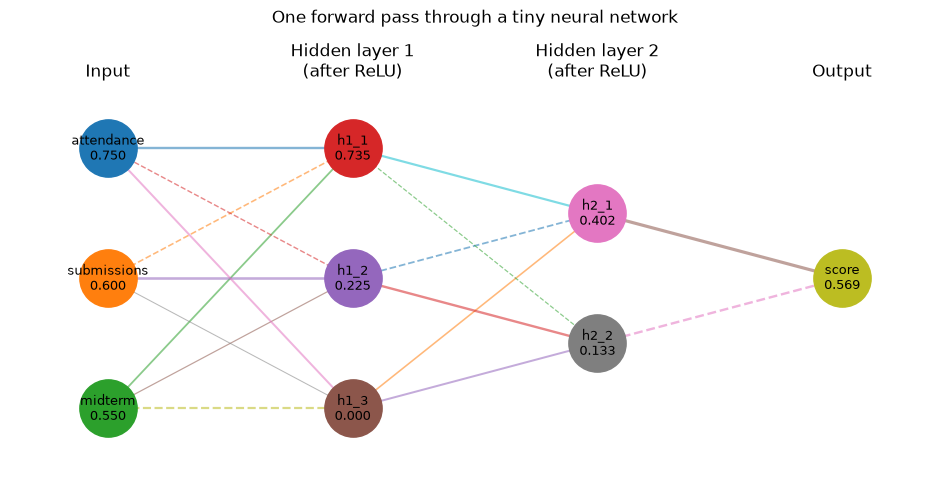

In [14]:
def plot_network_forward(inputs, activations1, activations2, output_score):
    fig, ax = plt.subplots(figsize=(12, 6))

    layer_x = [0, 1, 2, 3]
    ys = {
        0: np.array([2.0, 1.0, 0.0]),
        1: np.array([2.0, 1.0, 0.0]),
        2: np.array([1.5, 0.5]),
        3: np.array([1.0]),
    }

    values = {
        0: inputs,
        1: activations1,
        2: activations2,
        3: np.array([output_score]),
    }

    labels = {
        0: ["attendance", "submissions", "midterm"],
        1: ["h1_1", "h1_2", "h1_3"],
        2: ["h2_1", "h2_2"],
        3: ["score"],
    }

    weights_between = [W1, W2, W3]

    for layer_idx, weights in enumerate(weights_between):
        for target_idx in range(weights.shape[0]):
            for source_idx in range(weights.shape[1]):
                weight = weights[target_idx, source_idx]
                linestyle = "-" if weight >= 0 else "--"
                linewidth = 0.6 + 1.4 * abs(weight)
                ax.plot(
                    [layer_x[layer_idx], layer_x[layer_idx + 1]],
                    [ys[layer_idx][source_idx], ys[layer_idx + 1][target_idx]],
                    linestyle=linestyle,
                    linewidth=linewidth,
                    alpha=0.55,
                    zorder=1,
                )

    for layer_idx in range(4):
        for node_idx, y_pos in enumerate(ys[layer_idx]):
            ax.scatter(layer_x[layer_idx], y_pos, s=1700, zorder=3)
            ax.text(
                layer_x[layer_idx], y_pos,
                f"{labels[layer_idx][node_idx]}\n{values[layer_idx][node_idx]:.3f}",
                ha="center", va="center", fontsize=9, zorder=4,
            )

    ax.text(0, 2.55, "Input", ha="center", fontsize=12)
    ax.text(1, 2.55, "Hidden layer 1\n(after ReLU)", ha="center", fontsize=12)
    ax.text(2, 2.55, "Hidden layer 2\n(after ReLU)", ha="center", fontsize=12)
    ax.text(3, 2.55, "Output", ha="center", fontsize=12)

    ax.set_xlim(-0.4, 3.4)
    ax.set_ylim(-0.65, 2.9)
    ax.axis("off")
    ax.set_title("One forward pass through a tiny neural network")
    plt.show()

plot_network_forward(
    trace["input"],
    trace["layer1_post_relu"],
    trace["layer2_post_relu"],
    trace["score"][0],
)

### Activation values by stage

A second view is to plot the numbers at each stage separately. Look especially at the first hidden layer: one negative pre-activation becomes exactly zero after ReLU.

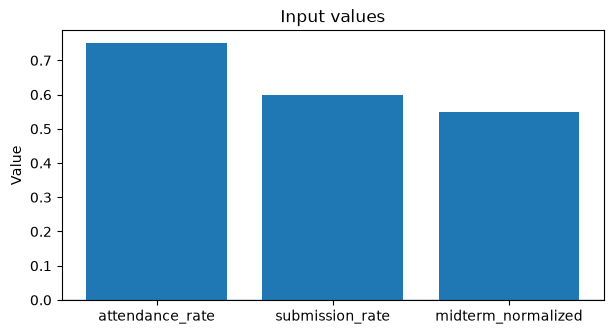

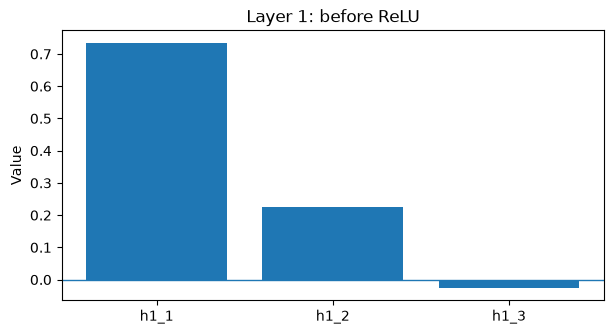

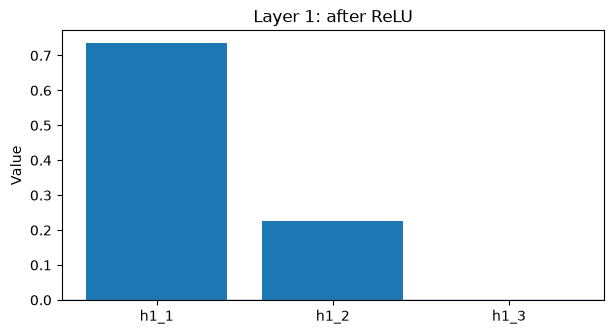

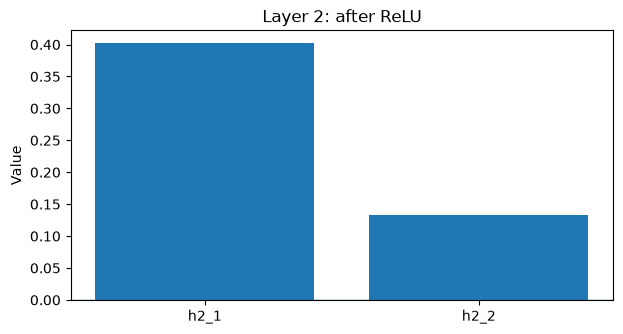

In [15]:
def plot_values(values, labels, title):
    plt.figure(figsize=(7, 3.5))
    plt.bar(labels, values)
    plt.axhline(0, linewidth=1)
    plt.ylabel("Value")
    plt.title(title)
    plt.show()

plot_values(trace["input"], feature_names, "Input values")
plot_values(trace["layer1_pre_relu"], ["h1_1", "h1_2", "h1_3"], "Layer 1: before ReLU")
plot_values(trace["layer1_post_relu"], ["h1_1", "h1_2", "h1_3"], "Layer 1: after ReLU")
plot_values(trace["layer2_post_relu"], ["h2_1", "h2_2"], "Layer 2: after ReLU")

## 10. What is data, what is learned, and what is temporary?

For this single forward pass:

| Kind of value | Examples | Role |
|---|---|---|
| **Input** | `0.75`, `0.60`, `0.55` | Comes from the current sample |
| **Parameters** | entries in `W1`, `W2`, `W3`, biases | Numbers stored inside the model |
| **Intermediate activations** | `a1`, `a2` | Temporary representations produced for this input |
| **Output** | `0.569` | Final result of the forward computation |

If we provide another input, the **activations and output change** while the fixed parameters stay the same.

In [16]:
second_input = np.array([0.90, 0.85, 0.80])
second_trace = forward_with_trace(second_input)

comparison = pd.DataFrame({
    "stage": ["input", "layer1_post_relu", "layer2_post_relu", "score"],
    "first sample": [
        trace["input"],
        trace["layer1_post_relu"],
        trace["layer2_post_relu"],
        trace["score"],
    ],
    "second sample": [
        second_trace["input"],
        second_trace["layer1_post_relu"],
        second_trace["layer2_post_relu"],
        second_trace["score"],
    ],
})
comparison

,stage,first sample,second sample
0,input,"[0.75, 0.6, 0.55]","[0.9, 0.85, 0.8]"
1,layer1_post_relu,"[0.735, 0.2250000000000001, 0.0]","[0.88, 0.455, 0.0]"
2,layer2_post_relu,"[0.4019999999999999, 0.13300000000000006]","[0.38849999999999996, 0.28800000000000003]"
3,score,[0.5685652990777049],[0.5338979215658985]


The model parameters did not change. Only the input changed, so the hidden representations and output changed.

That is the basic distinction between **the model** and **one execution of the model**.

## 11. Optional: reproduce the same network in PyTorch

The manual NumPy calculation is useful for understanding. Real deep-learning code normally uses a framework such as PyTorch.

PyTorch's `Linear` layer implements an affine transformation, and a forward hook can observe a module's output after its `forward()` computation. We will copy our hand-written parameters into PyTorch and verify that the framework produces the same answer.

This section uses **inference only**: no optimizer, loss, backward pass, or parameter update.

In [17]:
import importlib.util

TORCH_AVAILABLE = importlib.util.find_spec("torch") is not None

if not TORCH_AVAILABLE:
    print("PyTorch is not available in this runtime. The core notebook is complete; skip this optional section.")
else:
    import torch
    from torch import nn
    print("PyTorch:", torch.__version__)

PyTorch: 2.14.0+cpu


In [18]:
if TORCH_AVAILABLE:
    class TorchTinyNetwork(nn.Module):
        def __init__(self):
            super().__init__()
            self.layers = nn.Sequential(
                nn.Linear(3, 3),
                nn.ReLU(),
                nn.Linear(3, 2),
                nn.ReLU(),
                nn.Linear(2, 1),
                nn.Sigmoid(),
            )

        def forward(self, inputs):
            return self.layers(inputs)

    torch_model = TorchTinyNetwork()
    torch_model.eval()

    # Copy exactly the same fixed parameters used by NumPy.
    with torch.no_grad():
        torch_model.layers[0].weight.copy_(torch.tensor(W1, dtype=torch.float32))
        torch_model.layers[0].bias.copy_(torch.tensor(b1, dtype=torch.float32))
        torch_model.layers[2].weight.copy_(torch.tensor(W2, dtype=torch.float32))
        torch_model.layers[2].bias.copy_(torch.tensor(b2, dtype=torch.float32))
        torch_model.layers[4].weight.copy_(torch.tensor(W3, dtype=torch.float32))
        torch_model.layers[4].bias.copy_(torch.tensor(b3, dtype=torch.float32))

    print(torch_model)

TorchTinyNetwork(
  (layers): Sequential(
    (0): Linear(in_features=3, out_features=3, bias=True)
    (1): ReLU()
    (2): Linear(in_features=3, out_features=2, bias=True)
    (3): ReLU()
    (4): Linear(in_features=2, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


In [19]:
if TORCH_AVAILABLE:
    hook_log = {}
    handles = []

    layer_names = {
        0: "linear_1",
        1: "relu_1",
        2: "linear_2",
        3: "relu_2",
        4: "linear_3",
        5: "sigmoid",
    }

    def make_forward_hook(name):
        def hook(module, module_inputs, module_output):
            hook_log[name] = module_output.detach().cpu().numpy().copy()
        return hook

    for index, module in enumerate(torch_model.layers):
        handles.append(module.register_forward_hook(make_forward_hook(layer_names[index])))

    torch_input = torch.tensor(x, dtype=torch.float32)

    with torch.inference_mode():
        torch_output = torch_model(torch_input)

    for handle in handles:
        handle.remove()

    for name, value in hook_log.items():
        print(f"{name:10s} -> {value}")

    print("Final PyTorch score:", float(torch_output.item()))
    print("Final NumPy score:  ", float(score))

    assert np.allclose(torch_output.item(), score, atol=1e-6)
    print("Check passed: PyTorch and NumPy produce the same forward result.")
else:
    print("Skipped: PyTorch is not available.")

linear_1   -> [ 0.735  0.225 -0.025]
relu_1     -> [0.735 0.225 0.   ]
linear_2   -> [0.402 0.133]
relu_2     -> [0.402 0.133]
linear_3   -> [0.276]
sigmoid    -> [0.5686]
Final PyTorch score: 0.568565309047699
Final NumPy score:   0.5685652990777049
Check passed: PyTorch and NumPy produce the same forward result.


### Why the hook is useful

In the manual version, we explicitly saved `z1`, `a1`, `z2`, and `a2`. In a large model, rewriting every layer just to inspect intermediate values is inconvenient.

A **forward hook** lets us attach a small observer to a module and record its output when the model runs. This is useful later for debugging and visualizing activations.

One implementation detail matters in PyTorch: call the **module instance** (`model(x)`) rather than manually calling `model.forward(x)` when you want normal module behavior such as registered hooks.

## 12. Exercises

Try the exercises before looking at the optional solutions.

### Exercise 1 — Change the input

Use:

```python
x_ex1 = np.array([0.95, 0.90, 0.80])
```

1. Run it through `forward_with_trace`.
2. Record the Layer 1 activations, Layer 2 activations, and final score.
3. Compare them with the original sample.
4. Did the parameters change?

### Exercise 2 — Calculate one neuron by hand

Without using matrix multiplication, calculate the first Layer 1 pre-activation:

$$
z^{(1)}_1=0.8x_1-0.4x_2+0.5x_3+0.1.
$$

Check your answer against `trace["layer1_pre_relu"][0]`.

### Exercise 3 — Observe the ReLU gate

Try several input vectors and find one that makes at least **two** Layer 1 pre-activations negative.

Then answer:

- What are the corresponding values after ReLU?
- Did ReLU change the network parameters?
- Did ReLU change the architecture?

### Exercise 4 — Count parameters

Calculate the total number of parameters without using `.size`.

Use:

$$
\text{parameters in a Linear layer}
=\text{outputs}\times\text{inputs}+\text{outputs}.
$$

Verify that the complete model contains 23 parameters.

### Exercise 5 — Remove ReLU

Create a second forward function that uses no ReLU at all:

```text
input -> linear -> linear -> linear -> sigmoid
```

Compare its hidden values and final score with the original network.

What does this experiment tell you about the role of an activation function?

### Exercise 6 — Add one more layer (bonus)

Add another fixed `2 -> 2` linear layer plus ReLU between Layer 2 and the output layer.

You are not training anything. The purpose is simply to see that making a network "deeper" means composing more transformations.

### Concept questions

1. Which values belong to the input sample?
2. Which values are model parameters?
3. Which values exist only during this forward pass?
4. Why is the final `0.569` not evidence that the model is useful?
5. What would training need to change that this notebook never changes?

## 13. Optional solutions

Use these only after attempting the exercises.

In [20]:
# Exercise 1
x_ex1 = np.array([0.95, 0.90, 0.80])
trace_ex1 = forward_with_trace(x_ex1)

print("Layer 1 activations:", trace_ex1["layer1_post_relu"])
print("Layer 2 activations:", trace_ex1["layer2_post_relu"])
print("Final score:", trace_ex1["score"][0])
print("Parameters changed? No — forward_with_trace never modifies W1/W2/W3 or b1/b2/b3.")

Layer 1 activations: [0.9   0.485 0.   ]
Layer 2 activations: [0.3875 0.308 ]
Final score: 0.5296152941734261
Parameters changed? No — forward_with_trace never modifies W1/W2/W3 or b1/b2/b3.


In [21]:
# Exercise 2
z1_neuron1_by_hand = 0.8 * x[0] - 0.4 * x[1] + 0.5 * x[2] + 0.1
print("By hand:", z1_neuron1_by_hand)
print("From trace:", trace["layer1_pre_relu"][0])
assert np.allclose(z1_neuron1_by_hand, trace["layer1_pre_relu"][0])

By hand: 0.7350000000000001
From trace: 0.735


In [22]:
# Exercise 3 — one possible answer
x_ex3 = np.array([0.0, 0.0, 0.5])
trace_ex3 = forward_with_trace(x_ex3)

print("Layer 1 before ReLU:", trace_ex3["layer1_pre_relu"])
print("Layer 1 after ReLU: ", trace_ex3["layer1_post_relu"])
print("Negative values become zero; parameters and architecture are unchanged.")

Layer 1 before ReLU: [ 0.35 -0.1  -0.5 ]
Layer 1 after ReLU:  [0.35 0.   0.  ]
Negative values become zero; parameters and architecture are unchanged.


In [23]:
# Exercise 4
layer1_parameters = 3 * 3 + 3
layer2_parameters = 2 * 3 + 2
output_parameters = 1 * 2 + 1
manual_parameter_count = layer1_parameters + layer2_parameters + output_parameters

print("Layer 1:", layer1_parameters)
print("Layer 2:", layer2_parameters)
print("Output layer:", output_parameters)
print("Total:", manual_parameter_count)
assert manual_parameter_count == 23

Layer 1: 12
Layer 2: 8
Output layer: 3
Total: 23


In [24]:
# Exercise 5

def forward_without_relu(inputs):
    hidden1 = W1 @ inputs + b1
    hidden2 = W2 @ hidden1 + b2
    output_logit = W3 @ hidden2 + b3
    output_score = sigmoid(output_logit)
    return hidden1, hidden2, output_logit, output_score

h1_no_relu, h2_no_relu, logit_no_relu, score_no_relu = forward_without_relu(x)

print("With ReLU score:   ", score)
print("Without ReLU score:", score_no_relu[0])
print("Without ReLU hidden layer 1:", h1_no_relu)
print("Without ReLU hidden layer 2:", h2_no_relu)

With ReLU score:    0.5685652990777049
Without ReLU score: 0.5685652990777049
Without ReLU hidden layer 1: [ 0.735  0.225 -0.025]
Without ReLU hidden layer 2: [0.392 0.118]


In [25]:
# Exercise 6 — one possible extra layer
W_extra = np.array([
    [0.5, -0.3],
    [0.2,  0.7],
], dtype=float)
b_extra = np.array([0.05, -0.05], dtype=float)

W_out_deeper = np.array([[0.9, -0.6]], dtype=float)
b_out_deeper = np.array([0.02], dtype=float)


def forward_deeper(inputs):
    h1 = relu(W1 @ inputs + b1)
    h2 = relu(W2 @ h1 + b2)
    h3 = relu(W_extra @ h2 + b_extra)
    logit_deeper = W_out_deeper @ h3 + b_out_deeper
    score_deeper = sigmoid(logit_deeper)
    return h1, h2, h3, logit_deeper, score_deeper

h1_d, h2_d, h3_d, logit_d, score_d = forward_deeper(x)
print("Hidden layer 1:", h1_d)
print("Hidden layer 2:", h2_d)
print("Extra hidden layer:", h3_d)
print("Final score:", score_d[0])

Hidden layer 1: [0.735 0.225 0.   ]
Hidden layer 2: [0.402 0.133]
Extra hidden layer: [0.2111 0.1235]
Final score: 0.5339203180813381


### Concept questions — answers

1. **Input sample:** only the feature vector $\mathbf{x} = [0.75,\;0.60,\;0.55]$ (attendance, submission, midterm).
2. **Model parameters:** the weights and biases $W_1, b_1, W_2, b_2, W_3, b_3$ — 23 numbers in total.
3. **Values that exist only during this forward pass:** the intermediate results $\mathbf{z}^{(1)}, \mathbf{a}^{(1)}, \mathbf{z}^{(2)}, \mathbf{a}^{(2)}$, the output logit, and the final score. They are recomputed for every new input.
4. **Why `0.569` proves nothing:** the weights were picked by hand, not learned from data, and the score was never compared with real outcomes. It is just the output of an arbitrary function.
5. **What training would change:** the parameters ($W$ and $b$). A loss function would measure the error on labeled data, and backpropagation plus gradient descent would update the weights to reduce that error. This notebook never does either.


## 14. Checks and takeaways

Before moving on, make sure these statements make sense:

- A neural network can be viewed as a **function composed of smaller functions**.
- A forward pass takes an input and repeatedly transforms it through layers.
- A linear layer uses **weights and biases**; those are parameters.
- ReLU changes activations but is not itself a learned weight matrix.
- Hidden activations are temporary values created for a particular input.
- The same fixed model can produce different outputs for different inputs.
- A model can execute a forward pass even if its weights are useless.
- **Training is what would change the parameters. Nothing in this notebook trained the network.**

The next conceptual step is to study how a network obtains useful parameter values rather than the hand-written values used here.

## References and Colab compatibility notes

This notebook intentionally uses the open `.ipynb` Jupyter format and has no external data files. Google Colab supports uploading existing Jupyter/IPython notebooks from **File → Upload notebook**.

Useful official references:

- Google Colab FAQ: https://research.google.com/colaboratory/faq.html
- PyTorch `Linear`: https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html
- PyTorch modules and forward hooks: https://docs.pytorch.org/docs/stable/notes/modules.html
- PyTorch autograd modes / inference mode: https://docs.pytorch.org/docs/stable/notes/autograd.html

The core walkthrough does not depend on a particular PyTorch version. The optional PyTorch section uses stable APIs: `nn.Linear`, `nn.ReLU`, `register_forward_hook`, and `torch.inference_mode()`.